# Set 4: EDA + Single Layer Perceptron

**Q1 → Exp 1A / 1B** · **Q2 → Exp 4** (perceptron)

Datasets: Q1 `Stores.csv`, Q2 `Diabetes.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")      # hides library warnings so the output stays clean

---
## Question 1

### Q1.1 Read the data

In [2]:
df = pd.read_csv("data/Stores.csv")
print(df.shape)
df.head()

(50, 15)


,Branch,City,Customer,Gender,Product line,Unit_price,Quantity,Tax,Total,Payment,cogs,Rating,Age,Quarterly_Tax,Price
0,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,Ewallet,522.83,9.1,23.0,210.0,7469
1,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,Cash,76.40,9.6,23.0,210.0,1528
2,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,Credit card,324.31,7.4,24.0,210.0,4633
3,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,Ewallet,465.76,8.4,26.0,210.0,5822
4,A,Yangon,Normal,Male,Sports and travel,86.31,60,30.2085,634.3785,Ewallet,604.17,5.3,30.0,210.0,8631


### Q1.2 Identify the numerical columns: min, max and mean

In [3]:
num = df.select_dtypes("number")
print("Numerical columns:", list(num.columns))
pd.DataFrame({"min": num.min(), "max": num.max(), "mean": num.mean().round(2)})

Numerical columns: ['Unit_price', 'Quantity', 'Tax', 'Total', 'cogs', 'Rating', 'Age', 'Quarterly_Tax', 'Price']


,min,max,mean
Unit_price,14.480,99.42,60.24
Quantity,1.000,60.00,9.48
Tax,1.537,39.48,16.51
Total,32.277,829.08,346.67
cogs,30.740,789.60,331.29
Rating,4.100,9.90,6.80
Age,22.000,32.00,26.26
Quarterly_Tax,19.000,234.00,124.00
Price,1448.000,9942.00,6024.16


### Q1.3 Skewness with distribution plots: right, left and no skew

Unit_price      -0.26
Quantity         3.02
Tax              0.35
Total            0.35
cogs             0.36
Rating          -0.01
Age              0.15
Quarterly_Tax    0.76
Price           -0.26
dtype: float64

Right skew (> 0.5): ['Quantity', 'Quarterly_Tax']
Left skew (< -0.5): []
No skew  (-0.5 to 0.5): ['Unit_price', 'Tax', 'Total', 'cogs', 'Rating', 'Age', 'Price']


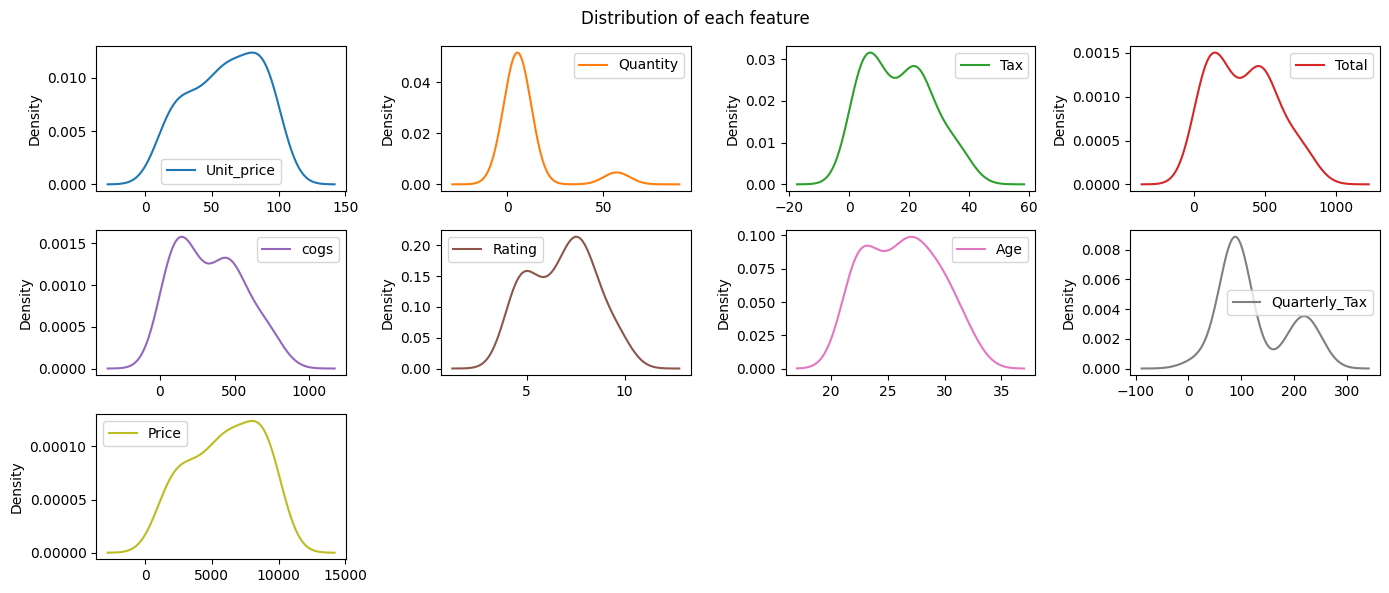

In [4]:
num = df.select_dtypes("number")
skew = num.skew()
print(skew.round(2))
print("\nRight skew (> 0.5):", list(skew[skew > 0.5].index))
print("Left skew (< -0.5):", list(skew[skew < -0.5].index))
print("No skew  (-0.5 to 0.5):", list(skew[skew.abs() <= 0.5].index))

num.plot(kind="kde", subplots=True, layout=(-1, 4), figsize=(14, 6), sharex=False, title="Distribution of each feature")
plt.tight_layout()
plt.show()

Right skew = long tail on the right (mean > median). Left skew = long tail on the left (mean < median).

### Q1.4 Mean imputation for numerical data if missing > 10%

In [5]:
pct = df.isnull().mean() * 100                      # % missing in every column
for col in df.select_dtypes("number").columns:
    if pct[col] > 10:
        df[col] = df[col].fillna(df[col].mean())
        print(f"{col}: {pct[col]:.1f}% missing -> filled with mean")
    else:
        print(f"{col}: {pct[col]:.1f}% missing -> not more than 10%, left as it is")

Unit_price: 0.0% missing -> not more than 10%, left as it is
Quantity: 0.0% missing -> not more than 10%, left as it is
Tax: 0.0% missing -> not more than 10%, left as it is
Total: 0.0% missing -> not more than 10%, left as it is
cogs: 6.0% missing -> not more than 10%, left as it is
Rating: 4.0% missing -> not more than 10%, left as it is
Age: 6.0% missing -> not more than 10%, left as it is
Quarterly_Tax: 4.0% missing -> not more than 10%, left as it is
Price: 0.0% missing -> not more than 10%, left as it is


No numerical column here is above 10%, so the code correctly leaves them. With your exam file, the same code fills the ones above 10%.

### Q1.5 Scaling with StandardScaler

In [6]:
from sklearn.preprocessing import StandardScaler

num = df.select_dtypes("number")
scaled = pd.DataFrame(StandardScaler().fit_transform(num), columns=num.columns)
print(scaled.describe().loc[["mean", "std"]].round(2))      # every column now has mean 0, std 1
scaled.head()

      Unit_price  Quantity   Tax  Total  cogs  Rating   Age  Quarterly_Tax  \
mean        0.00     -0.00 -0.00   0.00 -0.00   -0.00  0.00           0.00   
std         1.01      1.01  1.01   1.01  1.01    1.01  1.01           1.01   

      Price  
mean   0.00  
std    1.01  


,Unit_price,Quantity,Tax,Total,cogs,Rating,Age,Quarterly_Tax,Price
0,0.555602,-0.174041,0.906524,0.906524,0.887110,1.411434,-1.046327,1.365804,0.555602
1,-1.728964,-0.314396,-1.193984,-1.193984,-1.180517,1.718824,-1.046327,1.365804,-1.728964
2,-0.534960,-0.174041,-0.027537,-0.027537,-0.032330,0.366307,-0.724906,1.365804,-0.534960
3,-0.077739,-0.103863,0.638002,0.638002,0.622792,0.981087,-0.082065,1.365804,-0.077739
4,1.002441,3.545376,1.289239,1.289239,1.263833,-0.924733,1.203618,1.365804,1.002441


---
## Question 2

### Q2.1 Read and divide into training (70%) and testing (30%)

In [7]:
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/Diabetes.csv")
zero_is_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]   # a 0 here is impossible = missing
df[zero_is_missing] = df[zero_is_missing].replace(0, np.nan)
df = df.fillna(df.median())                           # fill with the median
X = StandardScaler().fit_transform(df.drop(columns="Outcome"))
y = df["Outcome"]
print(X.shape, y.value_counts().to_dict())

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

(768, 8) {0: 500, 1: 268}
Train: (537, 8)  Test: (231, 8)


### Q2.2 Build the model

In [8]:
from sklearn.linear_model import Perceptron

model = Perceptron(eta0=0.1, random_state=42).fit(X_train, y_train)
print("Weights:", model.coef_.round(3))
print("Bias   :", model.intercept_.round(3))

Weights: [[ 0.114  0.341 -0.245  0.081 -0.061  0.334  0.18  -0.006]]
Bias   : [-0.1]


### Q2.3 Evaluate on the test set: confusion table, Accuracy, Precision, Recall, F-measure

In [9]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

y_pred = model.predict(X_test)
print("Confusion table:")
print(confusion_matrix(y_test, y_pred))
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, average="macro"), 4))
print("Recall   :", round(recall_score(y_test, y_pred, average="macro"), 4))
print("F-measure:", round(f1_score(y_test, y_pred, average="macro"), 4))

Confusion table:
[[108  43]
 [ 25  55]]
Accuracy : 0.7056
Precision: 0.6866
Recall   : 0.7014
F-measure: 0.6893


### Q2.4 Plot the results

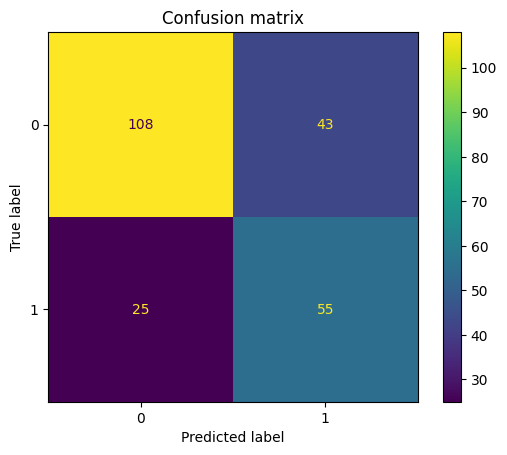

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion matrix")
plt.show()